In [11]:
# Import libraries
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

In [12]:
# Load your dataset
file_path = r"D:\basic python\sentiment Analaysis\mabel.txt"

with open(file_path, "r", encoding="utf-8") as file:
    lines = file.readlines()

messages = []

for line in lines:
    parts = line.strip().split(" - ", 1)

    if len(parts) == 2 and ": " in parts[1]:
        sender, message = parts[1].split(": ", 1)

        messages.append({
            "sender": sender,
            "text": message
        })

df = pd.DataFrame(messages)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Dataset shape: (52, 2)
Columns: ['sender', 'text']


,sender,text
0,Mabel Infoziant,Hi this is Mabel we just spoke
1,Mabel Infoziant,What’s your full name
2,AR❤,Ramisha Rani K
3,Mabel Infoziant,Ok
4,Mabel Infoziant,ramisharanik@gmail.com


In [13]:
# Clean the text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["cleaned_text"] = df["text"].apply(clean_text)

df = df[df["cleaned_text"].str.strip().ne("")].reset_index(drop=True)

df[["text", "cleaned_text"]].head()

,text,cleaned_text
0,Hi this is Mabel we just spoke,hi this is mabel we just spoke
1,What’s your full name,what s your full name
2,Ramisha Rani K,ramisha rani k
3,Ok,ok
4,ramisharanik@gmail.com,ramisharanik gmail com


In [14]:
# Apply TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=1000,
    min_df=1
)

tfidf_matrix = tfidf_vectorizer.fit_transform(df["cleaned_text"])

feature_names = tfidf_vectorizer.get_feature_names_out()

print("Documents:", tfidf_matrix.shape[0])
print("TF-IDF features:", tfidf_matrix.shape[1])
print("Matrix shape:", tfidf_matrix.shape)

Documents: 52
TF-IDF features: 132
Matrix shape: (52, 132)


In [16]:
# Display TF-IDF values
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=feature_names
)

tfidf_df.head()

,abstract,abstracts,address,analysis,arun,ask,asked,attached,auditor,brain,...,vignesh,visit,visited,waiting,whatsapp,work,working,ya,yeah,yes
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
# Build the LDA topic model
n_topics = 3

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=50,
    learning_method="batch"
)

lda_model.fit(tfidf_matrix)

print("Topic modeling completed!")

Topic modeling completed!


In [18]:
# Display the top 10 keywords for each topic
n_top_words = 10
topic_keywords = {}

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-n_top_words:][::-1]
    words = [feature_names[i] for i in top_indices]

    topic_keywords[topic_idx] = words

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(words))


Topic 1:
mam, yeah, yes, start, okay, cal, free, shall, hi, details

Topic 2:
ok, mam, sure, ramisha, send, hi, project, sent, updates, details

Topic 3:
tomorrow, needful, list, sorry, id, email, meeting, late, church, ramisharanik


In [19]:
# Assign topics to each message
topic_probabilities = lda_model.transform(tfidf_matrix)

df["dominant_topic"] = topic_probabilities.argmax(axis=1) + 1
df["topic_confidence"] = topic_probabilities.max(axis=1)

df[["sender", "text", "cleaned_text",
    "dominant_topic", "topic_confidence"]].head(10)

,sender,text,cleaned_text,dominant_topic,topic_confidence
0,Mabel Infoziant,Hi this is Mabel we just spoke,hi this is mabel we just spoke,2,0.765932
1,Mabel Infoziant,What’s your full name,what s your full name,1,0.333333
2,AR❤,Ramisha Rani K,ramisha rani k,2,0.720561
3,Mabel Infoziant,Ok,ok,2,0.665994
4,Mabel Infoziant,ramisharanik@gmail.com,ramisharanik gmail com,3,0.753605
5,Mabel Infoziant,Your email Id?,your email id,3,0.721678
6,AR❤,Yes Mam,yes mam,1,0.708300
7,Mabel Infoziant,I will send 2 abstracts for u to start working,i will send abstracts for u to start working,1,0.755612
8,AR❤,Yeah mam,yeah mam,1,0.708332
9,Mabel Infoziant,Give me the list that u have too,give me the list that u have too,3,0.664818


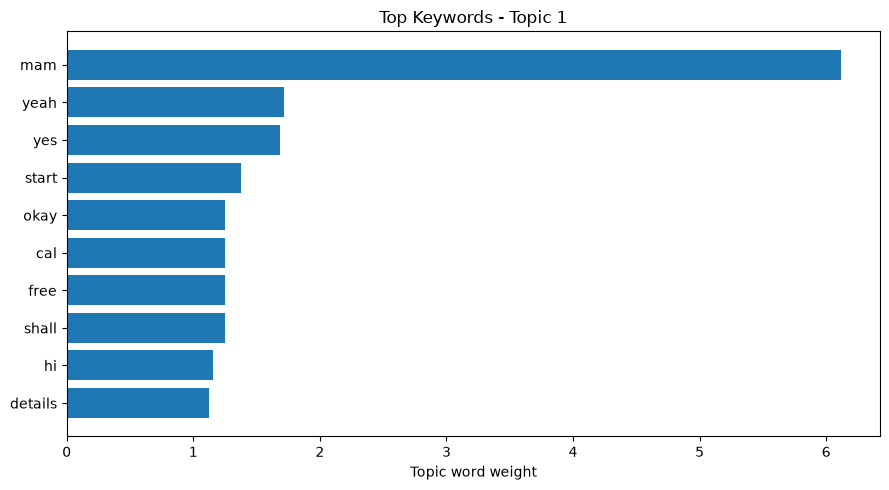

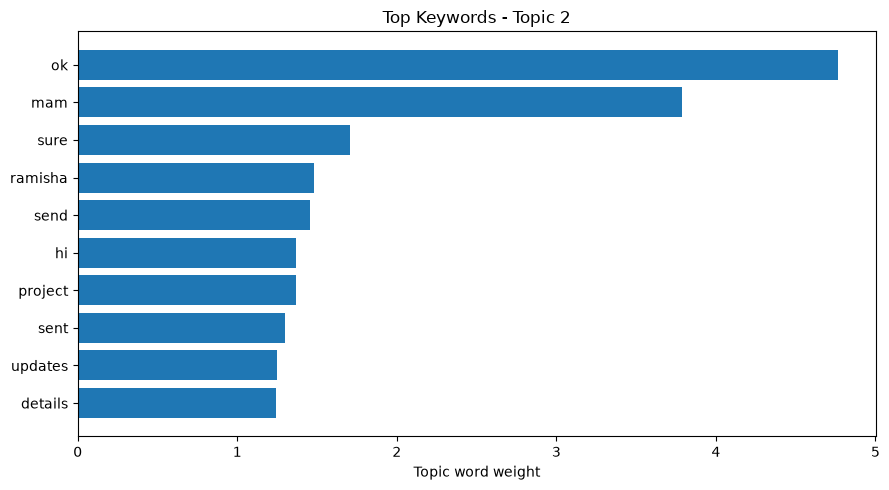

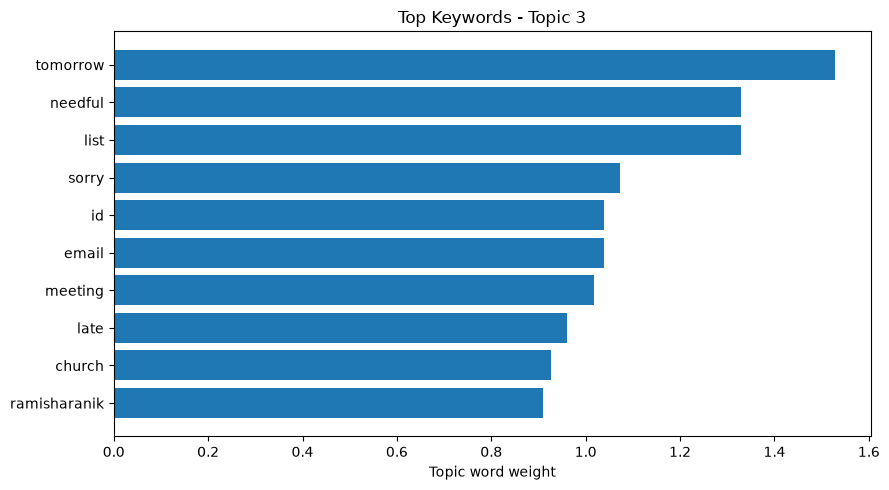

In [20]:
# Visualize topic keywords
for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-10:][::-1]

    words = [feature_names[i] for i in top_indices]
    weights = topic[top_indices]

    plt.figure(figsize=(9, 5))
    plt.barh(words[::-1], weights[::-1])
    plt.title(f"Top Keywords - Topic {topic_idx + 1}")
    plt.xlabel("Topic word weight")
    plt.tight_layout()
    plt.show()

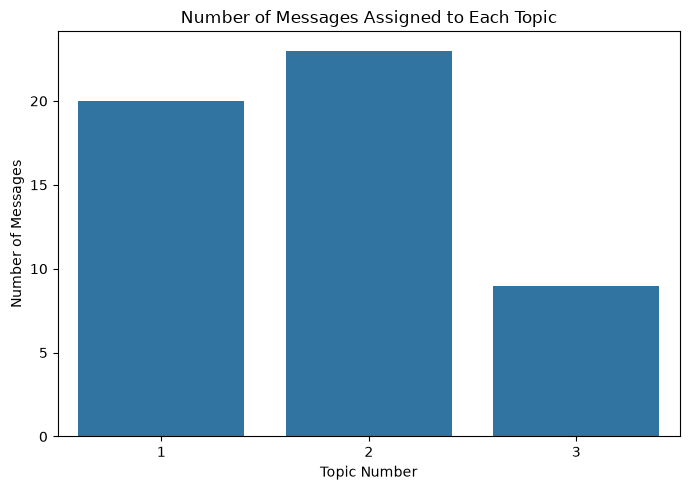

In [21]:
# Visualize messages per topic
topic_counts = df["dominant_topic"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(x=topic_counts.index, y=topic_counts.values)

plt.title("Number of Messages Assigned to Each Topic")
plt.xlabel("Topic Number")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()

In [22]:
# Export the results to CSV
df.to_csv(
    "mabel_tfidf_topic_modeling_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Results saved successfully!")

Results saved successfully!


In [23]:
# Export topic keywords
topic_results = pd.DataFrame([
    {
        "topic_number": topic_idx + 1,
        "top_keywords": ", ".join(words)
    }
    for topic_idx, words in topic_keywords.items()
])

topic_results.to_csv(
    "mabel_tfidf_topic_keywords.csv",
    index=False,
    encoding="utf-8-sig"
)

topic_results

,topic_number,top_keywords
0,1,"mam, yeah, yes, start, okay, cal, free, shall,..."
1,2,"ok, mam, sure, ramisha, send, hi, project, sen..."
2,3,"tomorrow, needful, list, sorry, id, email, mee..."
